<a href="https://colab.research.google.com/github/aureliearth/Analisis-Deret-Waktu/blob/main/data_ADW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.stattools import adfuller

In [ ]:
# Extracting the file ID from the provided Google Drive link
file_id = '1jgPeLoVV8ZrYG4hn-fnZ2muDDCmDpBsT'

# Using the export URL for Google Sheets/Excel stored on Drive
url = f'https://docs.google.com/spreadsheets/d/{file_id}/export?format=xlsx'

try:
    df = pd.read_excel(url)
    print("Dataset loaded successfully!")
    display(df.head())
except Exception as e:
    print("Error loading dataset. Please make sure the file is shared as 'Anyone with the link can view'.")
    print(e)

Dataset loaded successfully!


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
0,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,8010101021*,Color Chart Zillenial Colour System New ( 5 po...,ShowMeMore,1,750000,750000,0,0,750000
1,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,6,109000,654000,0,0,654000
2,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,12,116000,1392000,0,0,1392000
3,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1050202011,SLEEK ET LISSE Step 1 Strong Curly Hair 500 Ml,Straight System,3,159000,477000,0,0,477000
4,2026-03-01,ACC-SINV-2026-05723,ZIZE SALON - MEDAN,MDN,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,1,116000,116000,0,0,116000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34563 entries, 0 to 34562
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Tanggal        34562 non-null  datetime64[ns]
 1   Sales Invoice  34562 non-null  object        
 2   Customer       34562 non-null  object        
 3   Branch         34562 non-null  object        
 4   Item Code      34562 non-null  object        
 5   Item Name      34562 non-null  object        
 6   Sub Brand      34562 non-null  object        
 7   Qty            34563 non-null  int64         
 8   Harga          34563 non-null  int64         
 9   Total Harga    34563 non-null  int64         
 10  Retur          34563 non-null  int64         
 11  Diskon         34563 non-null  int64         
 12  Total          34563 non-null  int64         
dtypes: datetime64[ns](1), int64(6), object(6)
memory usage: 3.4+ MB


In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34563 entries, 0 to 34562
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Tanggal        34562 non-null  datetime64[ns]
 1   Sales Invoice  34562 non-null  object        
 2   Customer       34562 non-null  object        
 3   Branch         34562 non-null  object        
 4   Item Code      34562 non-null  object        
 5   Item Name      34562 non-null  object        
 6   Sub Brand      34562 non-null  object        
 7   Qty            34563 non-null  int64         
 8   Harga          34563 non-null  int64         
 9   Total Harga    34563 non-null  int64         
 10  Retur          34563 non-null  int64         
 11  Diskon         34563 non-null  int64         
 12  Total          34563 non-null  int64         
dtypes: datetime64[ns](1), int64(6), object(6)
memory usage: 3.4+ MB


,Tanggal,Qty,Harga,Total Harga,Retur,Diskon,Total
count,34562,34563.000000,3.456300e+04,3.456300e+04,3.456300e+04,3.456300e+04,3.456300e+04
mean,2026-04-28 05:00:01.458248704,5.538466,3.805443e+05,9.090358e+05,2.632060e+03,2.004585e+04,8.863579e+05
min,2026-03-01 00:00:00,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-2.900000e+06
25%,2026-03-28 00:00:00,1.000000,1.035000e+05,1.160000e+05,0.000000e+00,0.000000e+00,1.160000e+05
50%,2026-04-25 00:00:00,1.000000,1.250000e+05,2.100000e+05,0.000000e+00,0.000000e+00,2.090000e+05
75%,2026-05-30 00:00:00,3.000000,1.800000e+05,4.360000e+05,0.000000e+00,0.000000e+00,4.260000e+05
max,2026-06-30 00:00:00,95713.000000,6.576376e+09,1.570950e+10,4.548595e+07,3.464224e+08,1.531759e+10
std,NaN,514.838581,3.537451e+07,8.450676e+07,2.476581e+05,1.865345e+06,8.239885e+07


In [ ]:
# Hapus baris yang tidak memiliki tanggal
df = df.dropna(subset=["Tanggal"]).copy()

# Ubah kolom tanggal menjadi datetime
df["Tanggal"] = pd.to_datetime(
    df["Tanggal"],
    errors="coerce"
)

# Hapus tanggal yang gagal dikonversi
df = df.dropna(subset=["Tanggal"])

# Ubah Qty menjadi numerik
df["Qty"] = pd.to_numeric(
    df["Qty"],
    errors="coerce"
)

# Hapus transaksi dengan Qty tidak valid
df = df.dropna(subset=["Qty"])

# Periksa apakah kolom 'Sales Invoice' masih ada sebelum memisahkan retur
if "Sales Invoice" in df.columns:
    # Identifikasi jenis invoice
    df["Jenis_Invoice"] = np.where(
        df["Sales Invoice"].astype(str).str.contains(
            "RET",
            case=False,
            na=False
        ),
        "Invoice Retur",
        "Invoice Penjualan"
    )

    # Tampilkan jumlah transaksi
    print("Jumlah transaksi sebelum pemisahan:")
    display(df["Jenis_Invoice"].value_counts())

    # Pisahkan transaksi penjualan (tanpa retur)
    df = df[
        df["Jenis_Invoice"] == "Invoice Penjualan"
    ].copy()
else:
    print("Peringatan: Kolom 'Sales Invoice' tidak ditemukan karena kolom bertipe 'object' telah dihapus sebelumnya.")
    print("Pembersihan retur diabaikan.")

# Hilangkan komponen jam jika ada
df["Tanggal"] = df["Tanggal"].dt.normalize()

print("Ukuran data saat ini:", df.shape)
print("Total Qty penjualan:", df["Qty"].sum())

Jumlah transaksi sebelum pemisahan:


,count
Jenis_Invoice,
Invoice Penjualan,34392
Invoice Retur,170


Ukuran data saat ini: (34392, 14)
Total Qty penjualan: 95504


In [ ]:
# Jumlahkan Qty penjualan berdasarkan tanggal
data_harian = (
    df.groupby("Tanggal")["Qty"]
    .sum()
    .reset_index()
)

# Urutkan berdasarkan tanggal
data_harian = data_harian.sort_values("Tanggal")

# Tampilkan hasil
display(data_harian.head(10))

print("Jumlah observasi:", len(data_harian))
print("Total Qty penjualan:", data_harian["Qty"].sum())

,Tanggal,Qty
0,2026-03-01,62
1,2026-03-02,1009
2,2026-03-03,1025
3,2026-03-04,1052
4,2026-03-05,1063
5,2026-03-06,1351
6,2026-03-07,763
7,2026-03-08,261
8,2026-03-09,1592
9,2026-03-10,1151


Jumlah observasi: 119
Total Qty penjualan: 95504


In [ ]:
# Buat rentang tanggal harian lengkap
tanggal_lengkap = pd.date_range(
    start=data_harian["Tanggal"].min(),
    end=data_harian["Tanggal"].max(),
    freq="D"
)

# Jadikan tanggal sebagai index
data_harian = (
    data_harian
    .set_index("Tanggal")
    .reindex(tanggal_lengkap, fill_value=0)
)

# Beri nama index dan kolom
data_harian.index.name = "Tanggal"
data_harian.columns = ["Qty"]

# Tampilkan hasil
display(data_harian.head(15))

print("Jumlah observasi harian:", len(data_harian))

,Qty
Tanggal,
2026-03-01,62
2026-03-02,1009
2026-03-03,1025
2026-03-04,1052
2026-03-05,1063
2026-03-06,1351
2026-03-07,763
2026-03-08,261
2026-03-09,1592


Jumlah observasi harian: 122


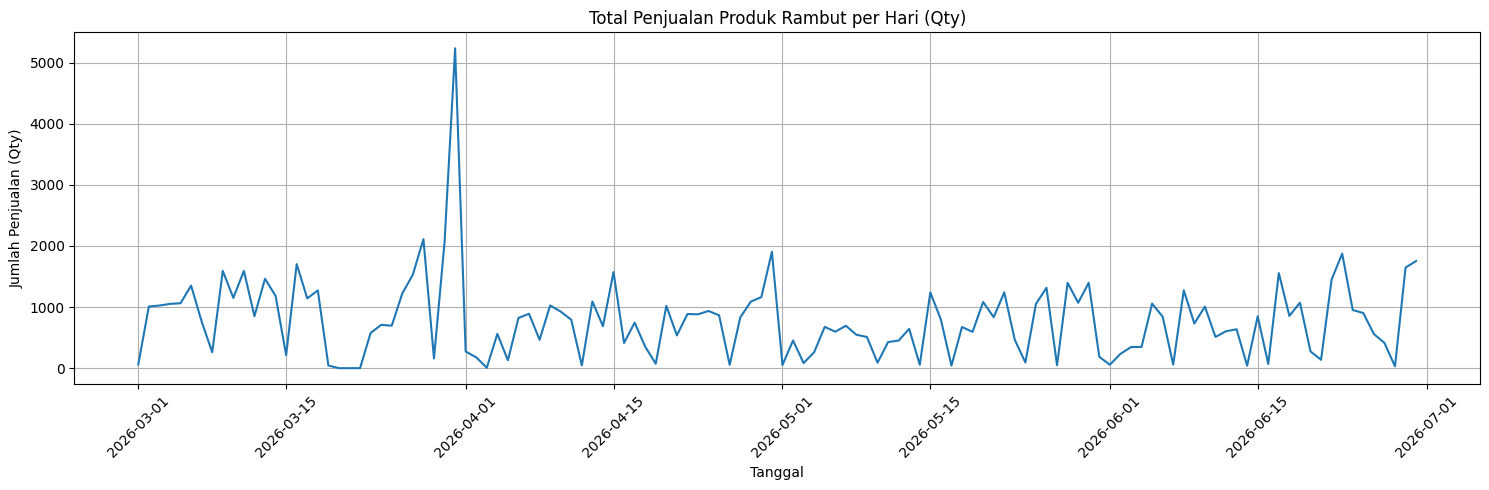

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    data_harian.index,
    data_harian["Qty"]
)

plt.title("Total Penjualan Produk Rambut per Hari (Qty)")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan (Qty)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss

# Convert to a 1D series to prevent shape alignment errors in KPSS
series_data = data_harian["Qty"]

hasil_adf = adfuller(series_data, autolag='AIC')

print("ADF Statistic:", hasil_adf[0])
print("p-value:", hasil_adf[1])
if hasil_adf[1] < 0.05:
    print("\nKesimpulan: Data STASIONER (ADF)")
else:
    print("\nKesimpulan: Data BELUM STASIONER (ADF)")

hasil_kpss = kpss(series_data, regression='c', nlags='auto')

print("\nKPSS Statistic:", hasil_kpss[0])
print("p-value:", hasil_kpss[1])
if hasil_kpss[1] < 0.05:
    print("\nKesimpulan: Data TIDAK STASIONER (KPSS)")
else:
    print("\nKesimpulan: Data STASIONER (KPSS)")

ADF Statistic: -9.415814419451188
p-value: 5.673470255621003e-16

Kesimpulan: Data STASIONER (ADF)

KPSS Statistic: 0.2157780113183211
p-value: 0.1

Kesimpulan: Data STASIONER (KPSS)


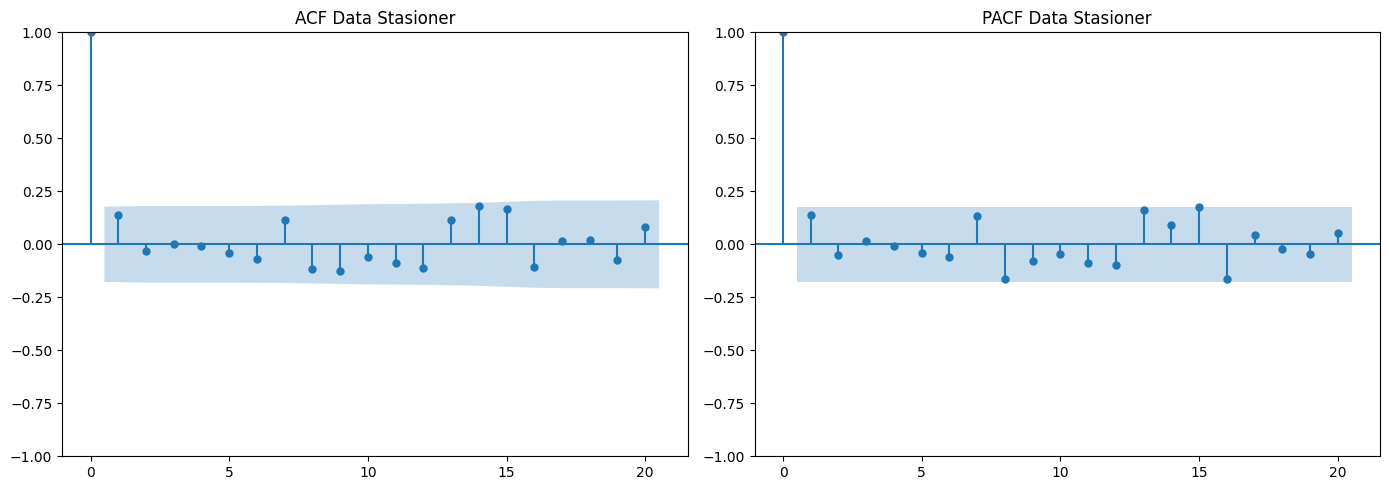

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, ax = plt.subplots(1, 2, figsize=(14,5))

plot_acf(data_harian["Qty"], lags=20, ax=ax[0])
ax[0].set_title("ACF Data Gross Qty")

plot_pacf(data_harian["Qty"], lags=20, ax=ax[1], method='ywm')
ax[1].set_title("PACF Data Gross Qty")

plt.tight_layout()
plt.show()